In [ ]:
from google.colab import drive
drive.mount('/content/drive');

In [ ]:
!unzip "/content/drive/MyDrive/emredata.zip"

###**Detectron2'yi Colab'a Yükleme**


In [ ]:
!pip install pyyaml==5.1
!pip install torch==1.8.0+cu101 torchvision==0.9.0+cu101 -f https://download.pytorch.org/whl/torch_stable.html
#install old version of pytorch since detectron2 hasn't released packages for pytorch 1.9

In [ ]:
!pip install detectron2 -f https://dl.fbaipublicfiles.com/detectron2/wheels/cu101/torch1.8/index.html
# After this step it will ask you to restart the runtime, please do it.

In [ ]:
import torch
assert torch.__version__.startswith("1.8") 
import torchvision
import cv2

In [ ]:
import os
import numpy as np
import json
import random
import matplotlib.pyplot as plt
%matplotlib inline

from detectron2.structures import BoxMode
from detectron2.data import DatasetCatalog, MetadataCatalog

### Burada, veri seti kendi özel formatındadır, bu nedenle onu ayrıştırmak ve onu dedektör2'nin standart formatına hazırlamak için bir fonksiyon yazıyoruz. Kullanıcı, özel biçimde bir veri kümesi kullanırken böyle bir işlevi kullanmalıdır.

###**Verileri Detectron2 Yapılandırmasına Uygun Şekilde Kaydetme**

Özel formata göre ayarlanacak

In [ ]:
def get_data_dicts(directory, classes):
    dataset_dicts = []
    for filename in [file for file in os.listdir(directory) if file.endswith('.json')]:              #  for filename in [file for file in os.listdir(directory) if file.endswith('.json')]:
        json_file = os.path.join(directory, filename)
        with open(json_file) as f:
            img_anns = json.load(f)

        record = {}
        
        filename = os.path.join(directory, img_anns["image_path"]) #imagePath faster RCNN\images\
        record["file_name"] = filename
        record["height"] = 512
        record["width"] = 512
        annos = img_anns["shapes"] #shapes
        objs = []
        for anno in annos:
            px = [a[0] for a in anno['coords']] # x coord
            py = [a[1] for a in anno['coords']] # y-coord
#            poly = [(x, y) for x, y in zip(px, py)] # poly for segmentation
#            poly = [p for x in poly for p in x]

            obj = {
                "bbox": [np.min(px), np.min(py), np.max(px), np.max(py)],
                "bbox_mode": BoxMode.XYXY_ABS,
                "category_id": classes.index(anno['label']),
                "iscrowd": 0
            }
            objs.append(obj)
        record["annotations"] = objs
        dataset_dicts.append(record)
        
    return dataset_dicts

Burada classlar eklenecek


In [ ]:
classes = ["apandiks-iltihabi" , "safra-kesesi-iltihabi","pankreas-iltihabi","bobrek-ureter-tasi", "bagirsak-divertikul-iltihabi","aort-anevrizma"] 

data_path = '/content/emredata/'

for d in ["train", "test"]:
    DatasetCatalog.register(
        "my_" + d, 
        lambda d=d: get_data_dicts(data_path+d, classes)
    )
    MetadataCatalog.get("my_" + d).set(thing_classes=classes)

microcontroller_metadata = MetadataCatalog.get("my_train")

###**Detectron2 Object Detection Modelinin Eğitimi**


In [ ]:
from detectron2 import model_zoo
from detectron2.engine import DefaultTrainer, DefaultPredictor
from detectron2.config import get_cfg
from detectron2.utils.visualizer import ColorMode, Visualizer
from matplotlib.patches import Rectangle

###**Yapılandırma Dosyasını Oluşturma**

Class sayısı ayarlanacak


In [ ]:
cfg = get_cfg() # Yapılandırma Dosyasını Oluşturuyoruz
cfg.merge_from_file(model_zoo.get_config_file("COCO-Detection/faster_rcnn_R_101_FPN_3x.yaml")) # Yapılandırma Dosyasını Çeker ve Yapılandırma Dosyasına Ekler
cfg.DATASETS.TRAIN = ("my_train",) # Train Verilerimiz Yapılandırma Dosyasına Kaydeder
cfg.DATASETS.TEST = ()
cfg.DATALOADER.NUM_WORKERS = 2 # Çalışan Sayısı
cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url("COCO-Detection/faster_rcnn_R_101_FPN_3x.yaml") # Ağırlıkları Çeker ve Yapılandırma Dosyasına Ekler
cfg.SOLVER.IMS_PER_BATCH = 2 # Batch Size
cfg.SOLVER.BASE_LR = 0.001 # Learning Rate (Öğrenme Oranı)
cfg.SOLVER.GAMMA = 0.05 # Learning Rate Azaltma Çarpımı
cfg.SOLVER.STEPS = [500] # Learning Rate Azaltma Adım Sayısı
cfg.TEST.EVAL_PERIOD = 200 # Eğitim Sırasında Modeli Değerlendirmek İçin Adım Sayısı

cfg.SOLVER.MAX_ITER = 2000 # İterasyon Sayısı
cfg.MODEL.ROI_HEADS.NUM_CLASSES = 6 # Sınıf Sayısı

In [ ]:
os.makedirs(cfg.OUTPUT_DIR, exist_ok=True) # Model Sonucu İçin Klasör Oluşturur
trainer = DefaultTrainer(cfg) # Modeli Train Moduna Geçirir Yapılandırma Dosyası ile Birlikte
trainer.resume_or_load(resume=False) # Model Eğitimine 0'dan Başlamak İçin False Yapıyoruz 

model_final_f6e8b1.pkl: 243MB [00:05, 47.3MB/s]                           
Skip loading parameter 'roi_heads.box_predictor.cls_score.weight' to the model due to incompatible shapes: (81, 1024) in the checkpoint but (7, 1024) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.cls_score.bias' to the model due to incompatible shapes: (81,) in the checkpoint but (7,) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.bbox_pred.weight' to the model due to incompatible shapes: (320, 1024) in the checkpoint but (24, 1024) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.bbox_pred.bias' to the model due to incompatible shapes: (320,) in the checkpoint but (24,) in the model! You might want to double check if this is expected.
Some model parameters or buffers are not found in the checkpoint:
roi_heads.box_p

In [ ]:
#trainer.train() # Model Eğitimine Başlar

In [ ]:
%load_ext tensorboard 
%tensorboard --logdir output

###**Eğitilmiş Model testi**

In [ ]:
#cfg.MODEL.WEIGHTS = os.path.join(cfg.OUTPUT_DIR, "model_final.pth") # Ağırlık Dosyamızı Yapılandırma Dosyamıza Kaydeder
cfg.MODEL.WEIGHTS = "/content/drive/MyDrive/teknofest deneme/model_final.pth"    #kayıtlı modeli çalıştırma
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.8 # Test için Eşik Değerimiz
cfg.DATASETS.TEST = ("my_test", ) # Tets Verilerimiz Yapılandırma Dosyasına Kaydeder
predictor = DefaultPredictor(cfg) #Modeli Test Moduna Geçirir Yapılandırma Dosyası ile Birlikte
test_metadata = MetadataCatalog.get("my_test")
test_dataset_dicts = get_data_dicts(data_path+'test', classes)

In [ ]:
os.mkdir("predict annot")

In [ ]:
from matplotlib.pyplot import figure
namelist = {}
for d in  test_dataset_dicts:     #random.sample(test_dataset_dicts,1)
      
    img = cv2.imread(d["file_name"])
    
    outputs = predictor(img)
    v = Visualizer(img[:, :, ::-1],
                   metadata=microcontroller_metadata, 
                   scale=0.8, 
                  # instance_mode=ColorMode.IMAGE_BW # removes the colors of unsegmented pixels
    )
    v = v.draw_instance_predictions(outputs["instances"].to("cpu"))

    plt.figure(figsize = (10, 10))
    plt.axis("off")
    plt.imshow(cv2.cvtColor(v.get_image()[:, :, ::-1], cv2.COLOR_BGR2RGB))
    plt.title(d["file_name"].split("/")[4])       #file name ayırma
    plt.show()
    
     
##   for x in range(len(outputs["instances"])):
#      #print(x)
#      deneme = outputs["instances"][x]
#      print(deneme)    

    
#               orjinal konumları yazdırma
#    print(d)  
#    annot = str(d)
#    print(annot,"\n")
#    print(annot.split("annotations")[1])
    
    
               


#               tahmin değerlerini txt dosyasına  yazdırma
    b = str(outputs["instances"]) 
    predictannot = b.split("tensor(")[1].strip(" device='cuda:0'), scores:")
#    print(b,"\n")# dosya formatını görmek isterseniz açın
#    print(predictannot)
    filename = str(d["file_name"].split("/")[4].strip(".jpg"))
#    print(filename)
   
    dosya = open("/content/predict annot/"+filename +".json", "w")
    dosya.write(predictannot)
    dosya.close()
   

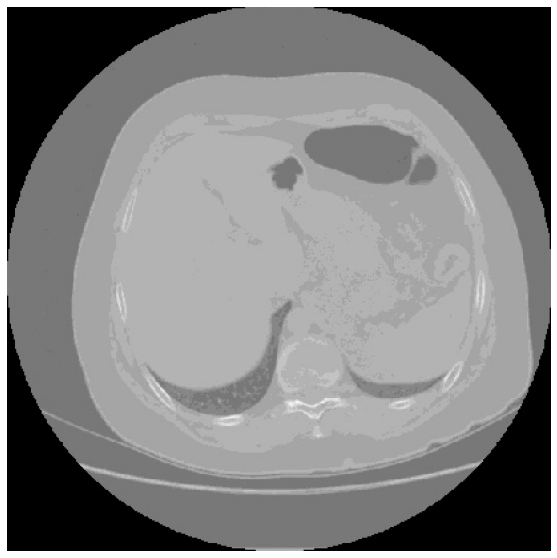

In [ ]:
from matplotlib.pyplot import figure
namelist = {}

      
img = cv2.imread("/content/emredata/test/23344_Seri2_32652310069.jpeg")

outputs = predictor(img)
v = Visualizer(img[:, :, ::-1],
               metadata=microcontroller_metadata, 
               scale=0.8, 
              # instance_mode=ColorMode.IMAGE_BW # removes the colors of unsegmented pixels
)
v = v.draw_instance_predictions(outputs["instances"].to("cpu"))
plt.figure(figsize = (10, 10))
plt.axis("off")
plt.imshow(cv2.cvtColor(v.get_image()[:, :, ::-1], cv2.COLOR_BGR2RGB))
   #file name ayırma
plt.show()

 
## for x in range(len(outputs["instances"])):
#    #print(x)
#    deneme = outputs["instances"][x]
#    print(deneme)   

#             orjinal konumları yazdırma
#  print(d)  
#  annot = str(d)
#  print(annot,"\n")
#  print(annot.split("annotations")[1])


          
#             tahmin değerlerini txt dosyasına  yazdırma
b = str(outputs["instances"]) 
predictannot = b.split("tensor(")[1].strip(" device='cuda:0'), scores:")
print(b,"\n")# dosya formatını görmek isterseniz açın
print(predictannot)



In [ ]:
"""def bb_intersection_over_union(boxA, boxB):
	# determine the (x, y)-coordinates of the intersection rectangle
	xA = max(boxA[0], boxB[0])
	yA = max(boxA[1], boxB[1])
	xB = min(boxA[2], boxB[2])
	yB = min(boxA[3], boxB[3])
	# compute the area of intersection rectangle
	interArea = max(0, xB - xA + 1) * max(0, yB - yA + 1)
	# compute the area of both the prediction and ground-truth
	# rectangles
	boxAArea = (boxA[2] - boxA[0] + 1) * (boxA[3] - boxA[1] + 1)
	boxBArea = (boxB[2] - boxB[0] + 1) * (boxB[3] - boxB[1] + 1)
	# compute the intersection over union by taking the intersection
	# area and dividing it by the sum of prediction + ground-truth
	# areas - the interesection area
	iou = interArea / float(boxAArea + boxBArea - interArea)
	# return the intersection over union value
	return iou"""

           0          1
0  56.262295   9.836066
1  92.874317  56.830601 

            0           1
0  140.961749   94.535519
1  177.300546  145.628415 

            0          1
0  188.502732  47.540984
1  226.207650  93.715847 



Text(0.5, 1.0, 'mavi orjinal kırmızı predict')

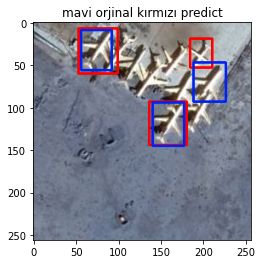

In [ ]:
import pandas as pd
import numpy as np
img = cv2.imread("/content/faster RCNN/test/airplane_239.jpg")
img = cv2.resize(img, (256,256))
df = pd.read_json("/content/predict annot/airplane_239.json")


for row in df.iterrows():
#  print(row,"\n\n\n")
  x1 = int(row[1][0])
  y1 = int(row[1][1])
  x2 = int(row[1][2])
  y2 = int(row[1][3])
  cv2.rectangle(img,(x1,y1),(x2,y2),(255,0,0), 2)

json_file = "/content/faster RCNN/test/airplane_239.json"
with open(json_file) as f:
    img_anns = json.load(f)

annos = img_anns["shapes"] #shapes
#print(annos,"\n")
listanno = []
for anno in annos:

  #print(anno["points"])
  dfanno = pd.DataFrame(anno['points'])
  print(dfanno,"\n")
  x1 = int(dfanno[0][0])
  y1 = int(dfanno[1][0])
  x2 = int(dfanno[0][1])
  y2 = int(dfanno[1][1])
  cv2.rectangle(img,(x1,y1),(x2,y2),(0,35,245), 2)
#  for row in dfanno.iterrows():
#    print(row)
#     x1 = int(row[0][0])
#     y1 = int(row[0][1])
#     x2 = int(row[1][0])
#     y2 = int(row[1][1])
#     cv2.rectangle(img,(x1,y1),(x2,y2),(0,255,0), 2)





#  for i in anno['points']:
#    
#    #print(i)
#    px = i[0]
#    py = i[1]
#    listanno.append(px)
#    listanno.append(py)
     # print(i[1])
   # px = [a[0] for a in anno['points']] # x coord
    #listanno.append(px)
   # py = [a[1] for a in anno['points']] # y-coord 
    #listanno.append(py)
#print(len(listanno))
#print(px):
#for x in range(len(listanno)):
#  px1 = listanno[0]
df = pd.DataFrame(listanno)
plt.figure()
plt.imshow(img)
plt.title("mavi orjinal kırmızı predict")
#print(df)


In [ ]:
import pandas as pd
import numpy as np
img = cv2.imread("//content/emredata/test/23344_Seri2_32652310069.jpeg")
img = cv2.resize(img, (512,512))
df = pd.read_json("/content/predict annot/23344_Seri2_32652310069.jpe.json")


for row in df.iterrows():

  x1 = int(row[1][0])
  y1 = int(row[1][1])
  x2 = int(row[1][2])
  y2 = int(row[1][3])
  cv2.rectangle(img,(x1,y1),(x2,y2),(255,0,0), 2)

json_file = "/content/emredata/test/23344_Seri2_32652310069.json"
with open(json_file) as f:
    img_anns = json.load(f)
annos = img_anns["shapes"] #shapes
#print(annos,"\n")
listanno = []
for anno in annos:

  #print(anno["points"])
  dfanno = pd.DataFrame(anno['points'])
  
  x1 = int(dfanno[0][0])
  y1 = int(dfanno[1][0])
  x2 = int(dfanno[0][1])
  y2 = int(dfanno[1][1])
  cv2.rectangle(img,(x1,y1),(x2,y2),(0,35,245), 2)



df = pd.DataFrame(listanno)
plt.figure()

plt.title("mavi orjinal kırmızı predict")
plt.imshow(img)


airplane
0.9578508568781844
airplane
0.9373913043478261
airplane
0.9361702127659575
airplane
0.008187772925764192
0.9433962264150944


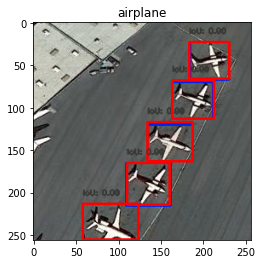

In [ ]:
import pandas as pd
import numpy as np
img = cv2.imread("/content/faster RCNN/test/airplane_220.jpg")
img = cv2.resize(img, (256,256))


dfpredict = pd.read_json("/content/predict annot/airplane_220.json")


json_file = "/content/faster RCNN/test/airplane_220.json"
with open(json_file) as f:
 
 img_anns = json.load(f)

annos = img_anns["shapes"] #shapes

a=1
for anno in annos:
 title = anno["label"]
 print(anno["label"]) 
 #print(anno["points"])
 dfanno = pd.DataFrame(anno['points']) #mavi orjinal
 
 x1 = int(dfanno[0][0])
 y1 = int(dfanno[1][0])
 x2 = int(dfanno[0][1])
 y2 = int(dfanno[1][1])
 cv2.rectangle(img,(x1,y1),(x2,y2),(0,35,245), 2)
 
 for row in dfpredict.iterrows():
       #predict kırmızı 
       
  xp1 = int(row[1][0])
  yp1 = int(row[1][1])
  xp2 = int(row[1][2])
  yp2 = int(row[1][3])

  xA = max(x1, xp1)
  yA = max(y1, yp1)
  xB = min(x2, xp2)
  yB = min(y2, yp2)

  interArea = max(0, xB - xA + 1) * max(0, yB - yA + 1)
  boxAArea = (x2 - x1 + 1) * (y2 - y1 + 1)
  boxBArea = (xp2 - xp1 + 1) * (yp2 - yp1 + 1)

  iou = interArea / float(boxAArea + boxBArea - interArea)  
 
  cv2.rectangle(img,(xp1,yp1),(xp2,yp2),(255,0,0), 2) 
  cv2.putText(img, "IoU: {:.2f}".format(iou), (xp1,yp1-10), cv2.FONT_HERSHEY_SIMPLEX,0.3, (55,55,52),1, cv2.LINE_AA)
   
  if(iou>0.007):
   print(iou) 
plt.figure()
plt.title(title,)
plt.imshow(img)


In [ ]:
max(+)

In [ ]:

"""import pandas as pd
import numpy as np
img = cv2.imread("/content/faster RCNN/test/airplane_217.jpg")
img = cv2.resize(img, (256,256))
df = pd.read_json("/content/predict annot5/airplane_218.json")

#plt.imshow(img)
for row in df.iterrows():
    x1 = float(row[1][0].split(" ")[0])
    y1 = float(row[1][0].split(" ")[1])
    x2 = float(row[1][0].split(" ")[2])
    y2 = float(row[1][0].split(" ")[3])
    cv2.rectangle(img,(x1,y1),(x2,y2),(255,0,0), 2)
#plt.figure()
#plt.imshow(img)"""

In [ ]:
"""image = cv2.imread("/content/faster RCNN/test/airplane_217.jpg")
	# draw the ground-truth bounding box along with the predicted
	# bounding box
cv2.rectangle(image, tuple(detection.gt[:2]), 
	tuple(detection.gt[2:]), (0, 255, 0), 2)
cv2.rectangle(image, tuple(detection.pred[:2]), 
	tuple(detection.pred[2:]), (0, 0, 255), 2)
# compute the intersection over union and display it
iou = bb_intersection_over_union(detection.gt, detection.pred)
cv2.putText(image, "IoU: {:.4f}".format(iou), (10, 30),
	cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)
#print("{}: {:.4f}".format(detection.image_path, iou))
# show the output image
cv2.imshow("Image", image)
cv2.waitKey(0)"""